# Lesson 19 — Forecasting for Public Health Surveillance and Emergency Response

**Scenario:** Weekly surveillance of acute febrile illness in a fictional district with two rainy seasons (long rains peaking in April, short rains in November). In 2025 a post-flood outbreak occurs. It is now the week of 3 November 2025, and the District Health Management Team needs a four-week outlook.

**Objective:** Apply current best practice in public health forecasting: correct recent weeks for reporting delays (nowcasting); detect unusual activity with epidemic thresholds; compare forecasts against simple baselines using only past data (rolling-origin evaluation); express forecasts as ranges and check that those ranges are trustworthy (coverage and weighted interval score); and communicate the outlook clearly.

**Data:** Synthetic weekly reports for January 2021 – November 2025, generated with a fixed random seed. Each week's cases arrive over up to four weeks, as in real reporting systems. The eventual complete counts are stored separately and used only to check the nowcast. No real patient data is used.

**Practice references:** WHO epidemic thresholds (mean + 2 SD); the US CDC FluSight challenge and the US and European COVID-19 Forecast Hubs (baseline comparison, quantile forecasts, weighted interval score, ensembles).

In [1]:
# Lesson 19 — Step 1: Five years of weekly surveillance reports, with reporting delays
import numpy as np
import pandas as pd
import duckdb
from pathlib import Path

rng = np.random.default_rng(19)

weeks = pd.date_range("2021-01-04", "2025-11-03", freq="W-MON")      # ISO weeks (Monday start)
t = np.arange(len(weeks))
week_of_year = weeks.isocalendar().week.to_numpy().astype(int)

# --- Expected weekly cases: population growth + two rainy seasons + a 2025 post-flood outbreak ---
trend = 120 * (1.03 ** (t / 52))                                           # about 3% growth a year
long_rains = 1.0 * np.exp(-((week_of_year - 17) ** 2) / (2 * 4 ** 2))      # peak late April
short_rains = 0.6 * np.exp(-((week_of_year - 47) ** 2) / (2 * 3.5 ** 2))   # peak late November
expected = trend * (1 + long_rains + short_rains)
flood = (weeks.year == 2025) & (week_of_year >= 20) & (week_of_year <= 34)
expected[flood] *= 1 + 1.6 * np.exp(-((week_of_year[flood] - 26) ** 2) / (2 * 3 ** 2))

# Eventually-complete counts, with more variation than pure chance (as in real surveillance)
final_cases = rng.negative_binomial(n=40, p=40 / (40 + expected))

# --- Reporting delay: share of each week's cases arriving 0, 1, 2, 3 or 4 weeks later ---
delay_share = np.array([0.45, 0.30, 0.13, 0.08, 0.04])
rows = [(wk.date(), d, int(c))
        for wk, n in zip(weeks, final_cases)
        for d, c in enumerate(rng.multinomial(n, delay_share))]
reports = pd.DataFrame(rows, columns=["onset_week", "delay_weeks", "cases"])

# The surveillance system only knows reports that have arrived by the extract date
extract_week = weeks[-1].date()
arrived = (pd.to_datetime(reports["onset_week"]) + pd.to_timedelta(7 * reports["delay_weeks"], "D")).dt.date
reports = reports[arrived <= extract_week].reset_index(drop=True)

# --- Save warehouse files; eventual true counts are sealed for checking the nowcast later ---
repo_root = Path.cwd().parent if Path.cwd().name == "lessons" else Path.cwd()
data_dir = repo_root / "data" / "weekly_surveillance"
data_dir.mkdir(parents=True, exist_ok=True)
truth = pd.DataFrame({"onset_week": weeks.date, "final_cases": final_cases})
con = duckdb.connect()
con.register("reports_df", reports)
con.register("truth_df", truth)
con.execute(f"COPY reports_df TO '{data_dir / 'reports_by_delay.parquet'}' (FORMAT parquet)")
con.execute(f"COPY truth_df TO '{data_dir / 'answer_key_final_counts.parquet'}' (FORMAT parquet)")

print(f"Weeks: {len(weeks)} ({weeks[0]:%d %b %Y} to {weeks[-1]:%d %b %Y}) | extract week: {extract_week}")
print(f"Reporting-table rows: {len(reports):,} | cases reported so far: {reports['cases'].sum():,}")
print("Saved:", sorted(p.name for p in data_dir.glob("*.parquet")))
del final_cases, truth, expected        # the analysis only sees what has been reported

Weeks: 253 (04 Jan 2021 to 03 Nov 2025) | extract week: 2025-11-03
Reporting-table rows: 1,255 | cases reported so far: 43,268
Saved: ['answer_key_final_counts.parquet', 'reports_by_delay.parquet']


## Step 2 — Nowcasting: Correcting Recent Weeks for Reporting Delays

Recent weeks are always incomplete because reports arrive over several weeks (right truncation). The completeness of reporting after 0, 1, 2 and 3 weeks is estimated from the last 52 fully reported weeks; each recent week's reported count is divided by its expected completeness to give a nowcast. The nowcast is then checked against the eventual complete counts.

SHARE OF CASES ARRIVED, BY WEEKS SINCE ONSET WEEK:


,delay_weeks,share_arrived
0,0,0.448
1,1,0.747
2,2,0.880
3,3,0.963
4,4,1.000



LATEST WEEKS — RAW REPORTS vs NOWCAST vs EVENTUAL TRUE COUNT:


,onset_week,weeks_observed,reported,nowcast,final_cases,reported_error_%,nowcast_error_%
0,2025-10-06,4,143.0,143.0,143,0.0,0.0
1,2025-10-13,3,160.0,166.0,166,-4.0,0.0
2,2025-10-20,2,182.0,207.0,210,-13.0,-1.0
3,2025-10-27,1,168.0,225.0,230,-27.0,-2.0
4,2025-11-03,0,92.0,205.0,206,-55.0,-0.0


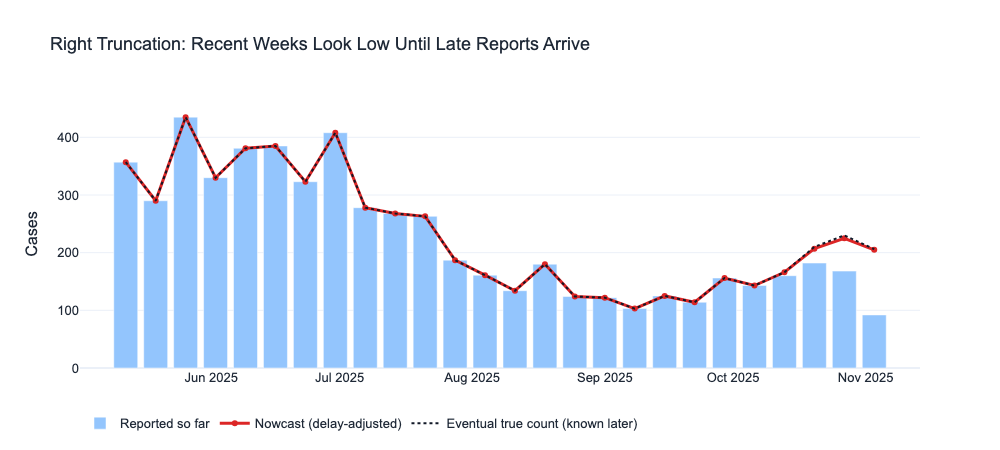

In [2]:
# Lesson 19 — Step 2: From delayed reports to a usable series — nowcasting the latest weeks
import plotly.io as pio
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pio.renderers.default = "plotly_mimetype+png"
HOUSE = dict(template="plotly_white", font=dict(family="Arial", size=13, color="#1F2937"),
             hoverlabel=dict(bgcolor="white", bordercolor="#9CA3AF", font=dict(size=12, color="#111827")))

wh = duckdb.connect()
wh.execute(f"CREATE OR REPLACE VIEW reports AS SELECT * FROM read_parquet('{data_dir / 'reports_by_delay.parquet'}')")
q = lambda sql: wh.sql(sql).df()

# --- 2a. Completeness: what share of a week's cases has arrived after 0, 1, 2, 3 weeks? ---
# Estimated from the last 52 fully reported weeks (onset at least 4 weeks before the extract)
completeness = q(f"""
WITH complete_weeks AS (
    SELECT * FROM reports
    WHERE onset_week <= DATE '{extract_week}' - INTERVAL 4 WEEK
      AND onset_week >  DATE '{extract_week}' - INTERVAL 56 WEEK
)
SELECT delay_weeks,
       round(sum(sum(cases)) OVER (ORDER BY delay_weeks) / sum(sum(cases)) OVER (), 3) AS share_arrived
FROM complete_weeks GROUP BY delay_weeks ORDER BY delay_weeks
""")
print("SHARE OF CASES ARRIVED, BY WEEKS SINCE ONSET WEEK:")
display(completeness)

# --- 2b. Weekly series with a nowcast for incomplete recent weeks ---
series = q(f"""
WITH weekly AS (
    SELECT onset_week, sum(cases) AS reported,
           least(date_diff('week', onset_week, DATE '{extract_week}'), 4) AS weeks_observed
    FROM reports GROUP BY onset_week
)
SELECT w.onset_week, w.reported, w.weeks_observed,
       coalesce(c.share_arrived, 1.0)                     AS share_arrived,
       round(w.reported / coalesce(c.share_arrived, 1.0)) AS nowcast
FROM weekly AS w
LEFT JOIN completeness AS c ON c.delay_weeks = w.weeks_observed AND w.weeks_observed < 4
ORDER BY w.onset_week
""")
series["onset_week"] = pd.to_datetime(series["onset_week"])

# --- 2c. Check the nowcast against the sealed eventual counts (known only weeks later) ---
truth = q(f"SELECT * FROM read_parquet('{data_dir / 'answer_key_final_counts.parquet'}')")
truth["onset_week"] = pd.to_datetime(truth["onset_week"])
recent = series.tail(5).merge(truth, on="onset_week")
recent["reported_error_%"] = (100 * (recent["reported"] - recent["final_cases"]) / recent["final_cases"]).round(0)
recent["nowcast_error_%"] = (100 * (recent["nowcast"] - recent["final_cases"]) / recent["final_cases"]).round(0)
print("\nLATEST WEEKS — RAW REPORTS vs NOWCAST vs EVENTUAL TRUE COUNT:")
display(recent[["onset_week", "weeks_observed", "reported", "nowcast", "final_cases",
                "reported_error_%", "nowcast_error_%"]])

# --- Figure: the last 26 weeks as reported, nowcast, and (later) confirmed ---
last = series.tail(26).merge(truth, on="onset_week")
fig = go.Figure()
fig.add_trace(go.Bar(x=last["onset_week"], y=last["reported"], name="Reported so far",
                     marker_color="#93C5FD", hovertemplate="Reported so far: <b>%{y}</b><extra></extra>"))
fig.add_trace(go.Scatter(x=last["onset_week"], y=last["nowcast"], name="Nowcast (delay-adjusted)",
                         mode="lines+markers", line=dict(color="#DC2626", width=3),
                         hovertemplate="Nowcast: <b>%{y}</b><extra></extra>"))
fig.add_trace(go.Scatter(x=last["onset_week"], y=last["final_cases"], name="Eventual true count (known later)",
                         mode="lines", line=dict(color="#111827", width=2, dash="dot"),
                         hovertemplate="Eventual count: <b>%{y}</b><extra></extra>"))
fig.update_layout(**HOUSE, title="Right Truncation: Recent Weeks Look Low Until Late Reports Arrive",
                  height=450, width=1000, hovermode="x unified", yaxis_title="Cases",
                  legend=dict(orientation="h", yanchor="top", y=-0.15, xanchor="left", x=0))
fig.update_xaxes(hoverformat="Week of %d %b %Y")
fig.show()

## Step 3 — Early Warning: Epidemic Thresholds and Alert Rules

For each ISO week, the expected level and threshold (mean + 2 SD) are computed from 2021–2024, pooling each week with its neighbours (12 values per week). A single week above the threshold is treated as a signal to verify; two or more consecutive weeks above it trigger an alert. Excess cases are counts above the expected level during alert weeks.

Single-week signals (verify before acting): weeks [14, 34]
Alert weeks (2+ consecutive weeks above threshold): [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
First alert: ISO week 20 (week of 12 May 2025)
Excess cases above the historical average during alert weeks: 1,992


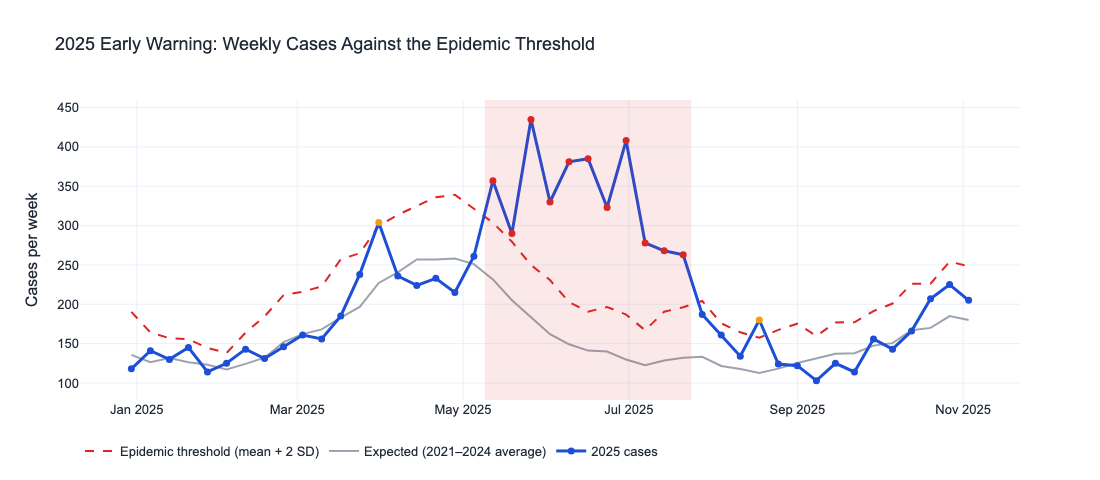

In [3]:
# Lesson 19 — Step 3: Early warning — epidemic thresholds and alert rules
series["cases"] = series["nowcast"]                      # best current estimate for every week
series["year"] = series["onset_week"].dt.isocalendar().year.astype(int)
series["iso_week"] = series["onset_week"].dt.isocalendar().week.astype(int)

# --- Threshold for each ISO week: historical mean + 2 SD (2021–2024) ---
# Each week's baseline pools that week and the weeks either side (3 weeks × 4 years = 12 values),
# which gives a smoother, more stable threshold than 4 values alone
hist = series[series["year"] <= 2024][["iso_week", "cases"]]
pooled = pd.concat([hist.assign(iso_week=(hist["iso_week"] - 1 + shift) % 52 + 1) for shift in (-1, 0, 1)])
baseline = pooled.groupby("iso_week")["cases"].agg(expected="mean", sd="std").reset_index()
baseline["threshold"] = baseline["expected"] + 2 * baseline["sd"]

y25 = series[series["year"] == 2025].merge(baseline, on="iso_week")
y25["above"] = y25["cases"] > y25["threshold"]
# Alert rule: at least 2 consecutive weeks above threshold (single-week signals are verified first)
y25["alert"] = y25["above"] & (y25["above"].shift(1, fill_value=False) | y25["above"].shift(-1, fill_value=False))

signals = y25.loc[y25["above"] & ~y25["alert"], "iso_week"].tolist()
alert_weeks = y25.loc[y25["alert"], "iso_week"].tolist()
first_alert = y25.loc[y25["alert"], "onset_week"].min()
print(f"Single-week signals (verify before acting): weeks {signals}")
print(f"Alert weeks (2+ consecutive weeks above threshold): {alert_weeks}")
print(f"First alert: ISO week {y25.loc[y25['alert'], 'iso_week'].min()} (week of {first_alert:%d %b %Y})")
excess = (y25.loc[y25["alert"], "cases"] - y25.loc[y25["alert"], "expected"]).sum()
print(f"Excess cases above the historical average during alert weeks: {excess:,.0f}")

# --- Figure: 2025 against the expected level and the epidemic threshold ---
fig = go.Figure()
fig.add_trace(go.Scatter(x=y25["onset_week"], y=y25["threshold"], name="Epidemic threshold (mean + 2 SD)",
                         line=dict(color="#DC2626", width=2, dash="dash"),
                         hovertemplate="Threshold: %{y:.0f}<extra></extra>"))
fig.add_trace(go.Scatter(x=y25["onset_week"], y=y25["expected"], name="Expected (2021–2024 average)",
                         line=dict(color="#9CA3AF", width=2), fill=None,
                         hovertemplate="Expected: %{y:.0f}<extra></extra>"))
fig.add_trace(go.Scatter(x=y25["onset_week"], y=y25["cases"], name="2025 cases",
                         mode="lines+markers", line=dict(color="#1D4ED8", width=3),
                         marker=dict(size=7, color=np.where(y25["alert"], "#DC2626",
                                                            np.where(y25["above"], "#F59E0B", "#1D4ED8"))),
                         customdata=np.column_stack([y25["iso_week"],
                                                     np.where(y25["alert"], "ALERT",
                                                              np.where(y25["above"], "Signal — verify", "Normal"))]),
                         hovertemplate="ISO week %{customdata[0]}: <b>%{y:.0f}</b> cases — %{customdata[1]}<extra></extra>"))
for _, block in y25[y25["alert"]].groupby((~y25["alert"]).cumsum()):
    fig.add_vrect(x0=block["onset_week"].min() - pd.Timedelta(days=3),
                  x1=block["onset_week"].max() + pd.Timedelta(days=3),
                  fillcolor="#DC2626", opacity=0.10, line_width=0)
fig.update_layout(**HOUSE, title="2025 Early Warning: Weekly Cases Against the Epidemic Threshold",
                  height=480, width=1100, hovermode="x unified", yaxis_title="Cases per week",
                  legend=dict(orientation="h", yanchor="top", y=-0.12, xanchor="left", x=0))
fig.update_xaxes(hoverformat="Week of %d %b %Y")
fig.show()
fig_alert = fig

## Step 4 — Baselines, a Seasonal Model and an Ensemble (Rolling-Origin Evaluation)

At every week from January 2023, each method is trained only on data available up to that week and forecasts 1–4 weeks ahead. Forecasts are scored against the eventual counts, separately for a normal year (2024) and the outbreak year (2025). Skill is the percentage reduction in mean absolute error relative to the naive baseline.

2,280 forecasts from 144 weekly forecast dates (1–4 weeks ahead, 4 methods)

MEAN ABSOLUTE ERROR (cases per week), 1–4 weeks ahead:


period,2024 (normal year),2025 (outbreak year)
model,,
Seasonal Poisson regression,23.8,58.0
Ensemble (naive + seasonal Poisson),28.0,41.5
Seasonal naive (same week last year),29.5,72.6
Naive (last week),37.8,49.3


SKILL vs NAIVE BASELINE (% lower error; negative = worse than the baseline):


period,2024 (normal year),2025 (outbreak year)
model,,
Seasonal Poisson regression,37.0,-18.0
Ensemble (naive + seasonal Poisson),26.0,16.0
Seasonal naive (same week last year),22.0,-47.0
Naive (last week),0.0,0.0


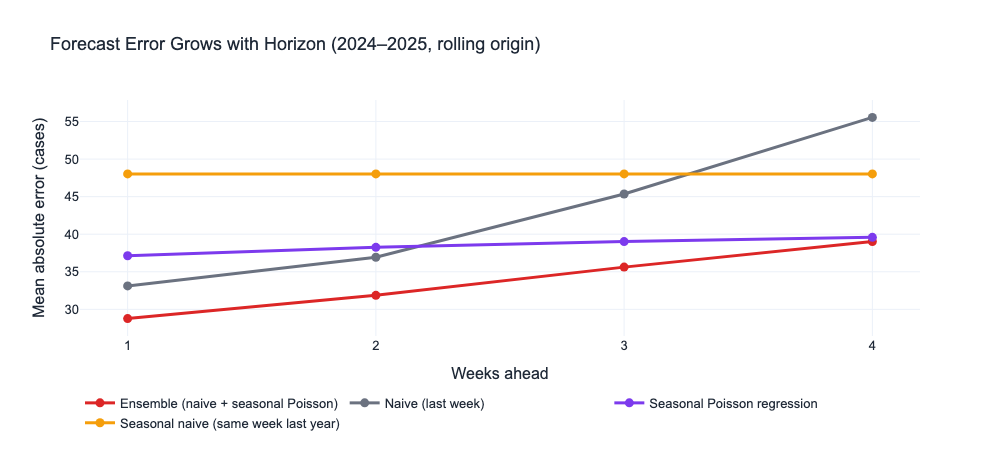

In [4]:
# Lesson 19 — Step 4: Baselines, a seasonal model and an ensemble — tested on the future only
from sklearn.linear_model import PoissonRegressor

y = series.set_index("onset_week")["cases"].astype(float)
last_complete = y.index[-1] - pd.Timedelta(weeks=4)          # targets must be fully reported to score

def season_X(dates):
    """Trend + yearly seasonal waves (Fourier terms: 3 pairs of sine/cosine)."""
    t = (dates - y.index[0]).days.to_numpy() / 7
    w = 2 * np.pi * t / 52.18
    return np.column_stack([t / 52] + [f(k * w) for k in (1, 2, 3) for f in (np.sin, np.cos)])

def point_forecasts(train, horizons=4):
    """1- to 4-week-ahead forecasts from four methods, using only data up to the forecast date."""
    future = train.index[-1] + pd.to_timedelta(7 * np.arange(1, horizons + 1), "D")
    seasonal = PoissonRegressor(alpha=1e-4, max_iter=1000).fit(season_X(train.index), train.values) \
                                                          .predict(season_X(future))
    naive = np.repeat(train.iloc[-1], horizons)
    return future, {
        "Naive (last week)": naive,
        "Seasonal naive (same week last year)": y.reindex(future - pd.Timedelta(weeks=52)).to_numpy(),
        "Seasonal Poisson regression": seasonal,
        "Ensemble (naive + seasonal Poisson)": (naive + seasonal) / 2,
    }

# --- Rolling-origin evaluation: every week from 2023, forecast the next 1–4 weeks ---
rows = []
for origin in y.index[(y.index >= "2023-01-02") & (y.index < last_complete)]:
    future, preds = point_forecasts(y[y.index <= origin])
    for model, values in preds.items():
        for h, (target, pred) in enumerate(zip(future, values), start=1):
            if target <= last_complete:
                rows.append((origin, h, target, model, pred, y[target]))
fc = pd.DataFrame(rows, columns=["origin", "horizon", "target", "model", "pred", "actual"])
fc["period"] = np.where(fc["target"].dt.year == 2025, "2025 (outbreak year)",
                        np.where(fc["target"].dt.year == 2024, "2024 (normal year)", "2023 (warm-up)"))
print(f"{len(fc):,} forecasts from {fc['origin'].nunique()} weekly forecast dates (1–4 weeks ahead, 4 methods)")

scored = fc[fc["period"] != "2023 (warm-up)"].assign(abs_error=lambda d: (d["pred"] - d["actual"]).abs())
mae = scored.pivot_table(index="model", columns="period", values="abs_error", aggfunc="mean")
naive_mae = mae.loc["Naive (last week)"]
skill = (1 - mae / naive_mae) * 100
print("\nMEAN ABSOLUTE ERROR (cases per week), 1–4 weeks ahead:")
display(mae.round(1).sort_values("2024 (normal year)"))
print("SKILL vs NAIVE BASELINE (% lower error; negative = worse than the baseline):")
display(skill.round(0).sort_values("2024 (normal year)", ascending=False))

# --- Figure: error grows with horizon ---
by_h = scored.groupby(["model", "horizon"])["abs_error"].mean().reset_index()
colors = {"Naive (last week)": "#6B7280", "Seasonal naive (same week last year)": "#F59E0B",
          "Seasonal Poisson regression": "#7C3AED", "Ensemble (naive + seasonal Poisson)": "#DC2626"}
fig = go.Figure()
for model, d in by_h.groupby("model"):
    fig.add_trace(go.Scatter(x=d["horizon"], y=d["abs_error"], name=model, mode="lines+markers",
                             line=dict(color=colors[model], width=3), marker=dict(size=9),
                             hovertemplate=f"<b>{model}</b><br>%{{x}}-week ahead: MAE %{{y:.1f}}<extra></extra>"))
fig.update_layout(**HOUSE, title="Forecast Error Grows with Horizon (2024–2025, rolling origin)",
                  height=450, width=1000, xaxis=dict(title="Weeks ahead", dtick=1),
                  yaxis_title="Mean absolute error (cases)",
                  legend=dict(orientation="h", yanchor="top", y=-0.22, xanchor="left", x=0))
fig.show()

## Step 5 — Prediction Intervals, Coverage and the Weighted Interval Score

Each method's 50%, 80% and 95% ranges are built from the spread of its own past errors at the same horizon, using only errors known at the forecast date (at least 26). Ranges are judged by coverage (the share of actual counts falling inside; ideally 50%, 80% and 95%) and by the weighted interval score (WIS), the standard scoring rule of the US and European COVID-19 Forecast Hubs, which rewards ranges that are both narrow and correct.

INTERVAL COVERAGE (% of actual counts inside each range; ideal = 50 / 80 / 95) AND WIS (lower = better):


inside_50%  \
period               model                                              
2024 (normal year)   Ensemble (naive + seasonal Poisson)         48.0   
                     Naive (last week)                           49.0   
                     Seasonal Poisson regression                 47.0   
                     Seasonal naive (same week last year)        51.0   
2025 (outbreak year) Ensemble (naive + seasonal Poisson)         48.0   
                     Naive (last week)                           49.0   
                     Seasonal Poisson regression                 38.0   
                     Seasonal naive (same week last year)        32.0   

                                                           inside_80%  \
period               model                                              
2024 (normal year)   Ensemble (naive + seasonal Poisson)         79.0   
                     Naive (last week)                           80.0   
                     Seasonal Poisson regression                 68.0   
                     Seasonal naive (same week last year)        75.0   
2025 (outbreak year) Ensemble (naive + seasonal Poisson)         76.0   
                     Naive (last week)                           80.0   
                     Seasonal Poisson regression                 64.0   
                     Seasonal naive (same week last year)        62.0   

                                                           inside_95%   WIS  
period               model                                                   
2024 (normal year)   Ensemble (naive + seasonal Poisson)         96.0  14.9  
                     Naive (last week)                           94.0  21.2  
                     Seasonal Poisson regression                 96.0  12.2  
                     Seasonal naive (same week last year)        92.0  16.0  
2025 (outbreak year) Ensemble (naive + seasonal Poisson)         87.0  24.3  
                     Naive (last week)                           94.0  26.5  
                     Seasonal Poisson regression                 76.0  42.6  
                     Seasonal naive (same week last year)        78.0  48.6

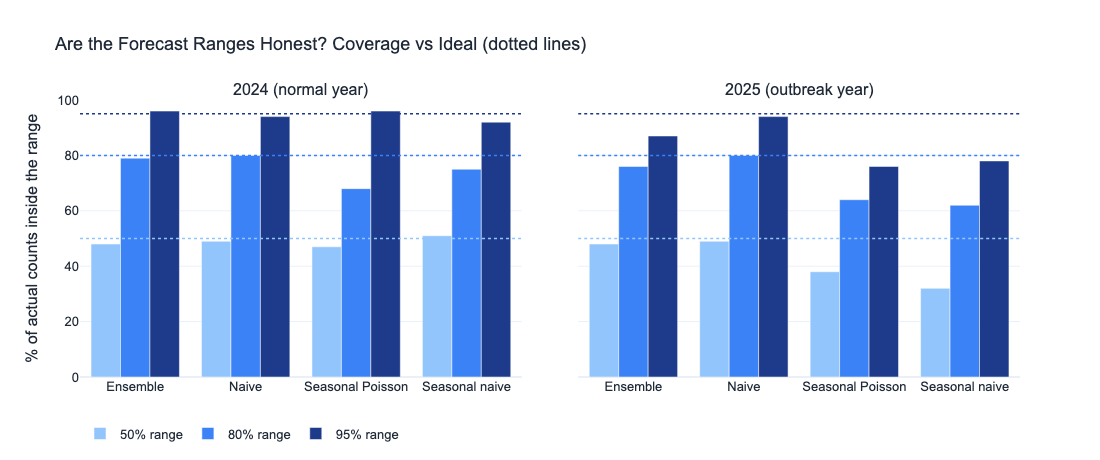

In [5]:
# Lesson 19 — Step 5: Forecast ranges (prediction intervals) and whether they can be trusted
quantile_levels = [0.025, 0.10, 0.25, 0.75, 0.90, 0.975]
fc["log_error"] = np.log((fc["actual"] + 1) / (fc["pred"] + 1))

def add_intervals(df):
    """Empirical intervals: spread of each method's own PAST errors at the same horizon.
    Only errors already known at the forecast date are used (no peeking at the future)."""
    out = []
    for (model, h), g in df.groupby(["model", "horizon"]):
        g = g.sort_values("origin")
        for _, row in g.iterrows():
            past = g.loc[g["target"] <= row["origin"], "log_error"]
            if len(past) < 26:                                   # need about 6 months of errors
                continue
            bounds = (row["pred"] + 1) * np.exp(np.quantile(past, quantile_levels)) - 1
            out.append({**row.to_dict(), **dict(zip(["lo95", "lo80", "lo50", "hi50", "hi80", "hi95"],
                                                    np.clip(bounds, 0, None)))})
    return pd.DataFrame(out)

iv = add_intervals(fc)
iv = iv[iv["period"] != "2023 (warm-up)"]

def interval_score(lo, hi, y, alpha):
    return (hi - lo) + (2 / alpha) * np.clip(lo - y, 0, None) + (2 / alpha) * np.clip(y - hi, 0, None)

# Weighted interval score (WIS): the standard scoring rule of the US and European COVID-19 Forecast Hubs
iv["WIS"] = (0.5 * (iv["pred"] - iv["actual"]).abs()
             + 0.05 / 2 * interval_score(iv["lo95"], iv["hi95"], iv["actual"], 0.05)
             + 0.20 / 2 * interval_score(iv["lo80"], iv["hi80"], iv["actual"], 0.20)
             + 0.50 / 2 * interval_score(iv["lo50"], iv["hi50"], iv["actual"], 0.50)) / 3.5
for level, lo, hi in [(50, "lo50", "hi50"), (80, "lo80", "hi80"), (95, "lo95", "hi95")]:
    iv[f"inside_{level}%"] = (iv["actual"] >= iv[lo]) & (iv["actual"] <= iv[hi])

calibration = (iv.groupby(["period", "model"])[["inside_50%", "inside_80%", "inside_95%", "WIS"]]
               .mean().round(2))
calibration[["inside_50%", "inside_80%", "inside_95%"]] *= 100
print("INTERVAL COVERAGE (% of actual counts inside each range; ideal = 50 / 80 / 95) AND WIS (lower = better):")
display(calibration.round(1))

# --- Figure: are the ranges honest? Coverage against the ideal levels ---
short = {"Naive (last week)": "Naive", "Seasonal naive (same week last year)": "Seasonal naive",
         "Seasonal Poisson regression": "Seasonal Poisson", "Ensemble (naive + seasonal Poisson)": "Ensemble"}
cov = calibration.reset_index()
fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.06,
                    subplot_titles=("2024 (normal year)", "2025 (outbreak year)"))
for col, period in enumerate(["2024 (normal year)", "2025 (outbreak year)"], start=1):
    d = cov[cov["period"] == period]
    for level, colour in [(50, "#93C5FD"), (80, "#3B82F6"), (95, "#1E3A8A")]:
        fig.add_trace(go.Bar(x=d["model"].map(short), y=d[f"inside_{level}%"], name=f"{level}% range",
                             marker_color=colour, showlegend=(col == 1), legendgroup=str(level),
                             customdata=d["WIS"],
                             hovertemplate=(f"<b>%{{x}}</b><br>Inside the {level}% range: <b>%{{y:.0f}}%</b>"
                                            f" (ideal {level}%)<br>WIS: %{{customdata:.1f}}<extra></extra>")),
                      row=1, col=col)
        fig.add_hline(y=level, line_dash="dot", line_color=colour, line_width=1.5, row=1, col=col)
fig.update_layout(**HOUSE, title="Are the Forecast Ranges Honest? Coverage vs Ideal (dotted lines)",
                  height=460, width=1100, barmode="group", yaxis_title="% of actual counts inside the range",
                  legend=dict(orientation="h", yanchor="top", y=-0.15, xanchor="left", x=0))
fig.update_yaxes(range=[0, 100])
fig.show()

## Step 6 — Forecasts at Outbreak Onset: Why Forecasting and Early Warning Are Different Tools

One-week-ahead forecasts from the seasonal Poisson model and the ensemble are compared with actual counts through 2025, with the threshold alert period shaded. The table shows forecasts during the weeks around outbreak onset (ISO weeks 18–24).

1-WEEK-AHEAD FORECASTS AROUND OUTBREAK ONSET (ISO weeks 18–24):


,model,Seasonal Poisson regression,Naive (last week),Ensemble (naive + seasonal Poisson)
iso_week,actual,,,
18,215.0,266.0,233.0,249.0
19,261.0,253.0,215.0,234.0
20,357.0,240.0,261.0,250.0
21,290.0,229.0,357.0,293.0
22,435.0,213.0,290.0,252.0
23,330.0,205.0,435.0,320.0
24,381.0,193.0,330.0,262.0


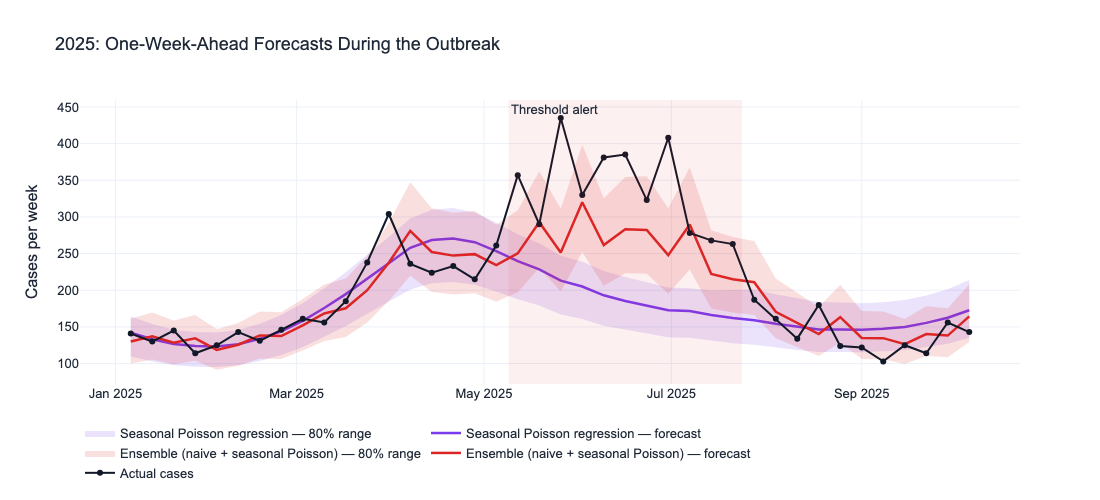

In [6]:
# Lesson 19 — Step 6: What happened when the outbreak began?
one_week = iv[(iv["horizon"] == 1) & (iv["target"].dt.year == 2025)].copy()
one_week["iso_week"] = one_week["target"].dt.isocalendar().week.astype(int)

print("1-WEEK-AHEAD FORECASTS AROUND OUTBREAK ONSET (ISO weeks 18–24):")
onset_view = one_week[one_week["iso_week"].between(18, 24)].pivot_table(
    index=["iso_week", "actual"], columns="model", values="pred").round(0)
display(onset_view[["Seasonal Poisson regression", "Naive (last week)",
                    "Ensemble (naive + seasonal Poisson)"]])

fig = go.Figure()
for model, colour, fill in [("Seasonal Poisson regression", "#7C3AED", "rgba(124,58,237,0.15)"),
                            ("Ensemble (naive + seasonal Poisson)", "#DC2626", "rgba(220,38,38,0.15)")]:
    d = one_week[one_week["model"] == model].sort_values("target")
    fig.add_trace(go.Scatter(x=pd.concat([d["target"], d["target"][::-1]]),
                             y=pd.concat([d["hi80"], d["lo80"][::-1]]), mode="lines", fill="toself", fillcolor=fill,
                             line=dict(width=0), name=f"{model} — 80% range", hoverinfo="skip"))
    fig.add_trace(go.Scatter(x=d["target"], y=d["pred"], name=f"{model} — forecast",
                             line=dict(color=colour, width=2.5),
                             hovertemplate=f"{model}: <b>%{{y:.0f}}</b><extra></extra>"))
actual = one_week.drop_duplicates("target").sort_values("target")
fig.add_trace(go.Scatter(x=actual["target"], y=actual["actual"], name="Actual cases", mode="lines+markers",
                         line=dict(color="#111827", width=2), marker=dict(size=6),
                         hovertemplate="Actual: <b>%{y:.0f}</b><extra></extra>"))
for _, block in y25[y25["alert"]].groupby((~y25["alert"]).cumsum()):
    fig.add_vrect(x0=block["onset_week"].min() - pd.Timedelta(days=3),
                  x1=block["onset_week"].max() + pd.Timedelta(days=3),
                  fillcolor="#DC2626", opacity=0.07, line_width=0,
                  annotation_text="Threshold alert", annotation_position="top left")
fig.update_layout(**HOUSE, title="2025: One-Week-Ahead Forecasts During the Outbreak",
                  height=500, width=1100, hovermode="x unified", yaxis_title="Cases per week",
                  legend=dict(orientation="h", yanchor="top", y=-0.12, xanchor="left", x=0))
fig.update_xaxes(hoverformat="Week of %d %b %Y")
fig.show()
fig_outbreak = fig

## Step 7 — Real-Time 4-Week Outlook

The ensemble is trained on all data available this week (recent weeks nowcast-corrected) and forecasts the next four weeks. Ranges come from the ensemble's past errors at each horizon. The outlook is shown as a fan chart against the epidemic threshold, with an automatically generated situation statement for decision-makers.

4-WEEK OUTLOOK (ensemble forecast with 50%, 80% and 95% ranges):


,forecast,lo80,hi80,lo95,hi95,expected,threshold
week_starting,,,,,,,
2025-11-10,216.0,170.0,274.0,145.0,316.0,192.0,265.0
2025-11-17,218.0,165.0,275.0,149.0,320.0,194.0,259.0
2025-11-24,218.0,162.0,284.0,139.0,334.0,200.0,267.0
2025-12-01,215.0,155.0,286.0,135.0,328.0,188.0,259.0



SITUATION STATEMENT:
Over the next four weeks, cases are expected to stay around 217 per week (80% range 155–286), above the usual level for this time of year (194). The central forecast stays below the epidemic threshold; the upper 95% range crosses it, so weekly monitoring should continue through the short-rains season.


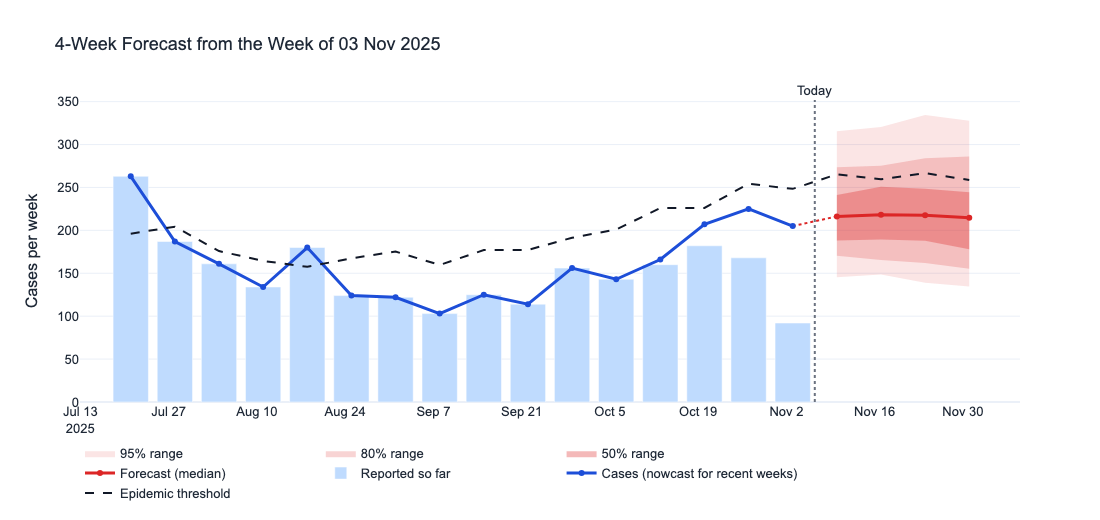

In [7]:
# Lesson 19 — Step 7: The real-time forecast — next 4 weeks, with uncertainty
ensemble_name = "Ensemble (naive + seasonal Poisson)"
future, preds = point_forecasts(y)                              # trained on all data up to this week
central = preds[ensemble_name]

# Ranges from the ensemble's full error history at each horizon
past_errors = fc[fc["model"] == ensemble_name]
outlook = pd.DataFrame({"week_starting": future, "horizon": range(1, 5), "forecast": central})
for h in range(1, 5):
    errs = past_errors.loc[past_errors["horizon"] == h, "log_error"]
    q = (central[h - 1] + 1) * np.exp(np.quantile(errs, quantile_levels)) - 1
    outlook.loc[outlook["horizon"] == h, ["lo95", "lo80", "lo50", "hi50", "hi80", "hi95"]] = np.clip(q, 0, None)
outlook["iso_week"] = outlook["week_starting"].dt.isocalendar().week.astype(int)
outlook = outlook.merge(baseline[["iso_week", "expected", "threshold"]], on="iso_week")
print("4-WEEK OUTLOOK (ensemble forecast with 50%, 80% and 95% ranges):")
display(outlook.set_index("week_starting")[["forecast", "lo80", "hi80", "lo95", "hi95", "expected", "threshold"]].round(0))

# Plain-language situation statement, generated from the numbers
level = "above" if outlook["forecast"].mean() > outlook["expected"].mean() else "below"
below = (outlook["forecast"] < outlook["threshold"]).all()
upper_crosses = (outlook["hi95"] > outlook["threshold"]).any()
statement = (f"Over the next four weeks, cases are expected to stay around {outlook['forecast'].mean():.0f} per week "
             f"(80% range {outlook['lo80'].min():.0f}–{outlook['hi80'].max():.0f}), {level} the usual level "
             f"for this time of year ({outlook['expected'].mean():.0f}). The central forecast stays "
             f"{'below' if below else 'above'} the epidemic threshold; the upper 95% range "
             f"{'crosses' if upper_crosses else 'stays below'} it, so weekly monitoring should continue "
             f"through the short-rains season.")
print("\nSITUATION STATEMENT:\n" + statement)

# --- Fan chart: recent history, nowcast and the 4-week forecast ---
recent16 = series.tail(16)
fig = go.Figure()
for lo, hi, alpha, label in [("lo95", "hi95", 0.12, "95% range"), ("lo80", "hi80", 0.20, "80% range"),
                             ("lo50", "hi50", 0.32, "50% range")]:
    fig.add_trace(go.Scatter(x=pd.concat([outlook["week_starting"], outlook["week_starting"][::-1]]),
                             y=pd.concat([outlook[hi], outlook[lo][::-1]]), mode="lines", fill="toself",
                             fillcolor=f"rgba(220,38,38,{alpha})", line=dict(width=0), name=label,
                             hoverinfo="skip"))
fig.add_trace(go.Scatter(x=outlook["week_starting"], y=outlook["forecast"], name="Forecast (median)",
                         mode="lines+markers", line=dict(color="#DC2626", width=3),
                         customdata=outlook[["lo80", "hi80", "lo95", "hi95"]],
                         hovertemplate=("Forecast: <b>%{y:.0f}</b><br>80% range: %{customdata[0]:.0f}–%{customdata[1]:.0f}"
                                        "<br>95% range: %{customdata[2]:.0f}–%{customdata[3]:.0f}<extra></extra>")))
fig.add_trace(go.Scatter(x=[y.index[-1], outlook["week_starting"].iloc[0]],
                         y=[y.iloc[-1], outlook["forecast"].iloc[0]], mode="lines", showlegend=False,
                         line=dict(color="#DC2626", width=2, dash="dot"), hoverinfo="skip"))
fig.add_trace(go.Bar(x=recent16["onset_week"], y=recent16["reported"], name="Reported so far",
                     marker_color="#BFDBFE", hovertemplate="Reported so far: %{y:.0f}<extra></extra>"))
fig.add_trace(go.Scatter(x=recent16["onset_week"], y=recent16["nowcast"], name="Cases (nowcast for recent weeks)",
                         mode="lines+markers", line=dict(color="#1D4ED8", width=3),
                         hovertemplate="Cases (nowcast): <b>%{y:.0f}</b><extra></extra>"))
thr = pd.concat([recent16[["onset_week", "iso_week"]],
                 outlook[["week_starting", "iso_week"]].rename(columns={"week_starting": "onset_week"})])
thr = thr.merge(baseline[["iso_week", "threshold"]], on="iso_week")
fig.add_trace(go.Scatter(x=thr["onset_week"], y=thr["threshold"], name="Epidemic threshold",
                         line=dict(color="#111827", width=2, dash="dash"),
                         hovertemplate="Threshold: %{y:.0f}<extra></extra>"))
fig.add_vline(x=y.index[-1] + pd.Timedelta(days=3.5), line_dash="dot", line_color="#6B7280",
              annotation_text="Today", annotation_position="top")
fig.update_layout(**HOUSE, title=f"4-Week Forecast from the Week of {y.index[-1]:%d %b %Y}",
                  height=520, width=1100, hovermode="x unified", yaxis_title="Cases per week",
                  legend=dict(orientation="h", yanchor="top", y=-0.12, xanchor="left", x=0))
fig.update_xaxes(hoverformat="Week of %d %b %Y")
fig.show()
fig_outlook = fig

## Step 8 — Publication Figures and Interactive Outlook

In [8]:
# Lesson 19 — Step 8: Save publication figures and the interactive outlook
fig_dir = repo_root / "figures"
docs_dir = repo_root / "docs"
docs_dir.mkdir(exist_ok=True)

fig_alert.write_image(fig_dir / "lesson19_early_warning.png", width=1100, height=480, scale=2)
fig_outlook.write_image(fig_dir / "lesson19_forecast_outlook.png", width=1100, height=520, scale=2)
fig_outbreak.write_image(fig_dir / "lesson19_outbreak_forecasts.png", width=1100, height=500, scale=2)

page = go.Figure(fig_outlook)
page.update_layout(width=None)
page.write_html(docs_dir / "forecast_outlook.html", include_plotlyjs="cdn",
                config={"displaylogo": False, "responsive": True})
print("Saved:", sorted(p.name for p in fig_dir.glob("lesson19_*.png")), "and docs/forecast_outlook.html")

Saved: ['lesson19_early_warning.png', 'lesson19_forecast_outlook.png', 'lesson19_outbreak_forecasts.png'] and docs/forecast_outlook.html


## Conclusions

1. **Nowcasting is essential.** Only 44.8% of a week's cases are reported in the same week. The raw count for the latest week (92) was 55% below the eventual total (206); the completeness-adjusted nowcast (205) was within 2% for every recent week. Without it, rising cases at the start of the short rains would have looked like a sharp decline.
2. **Thresholds detected the outbreak immediately.** Using WHO-style thresholds (mean + 2 SD of 2021–2024, pooled with neighbouring weeks), the post-flood outbreak triggered an alert from ISO week 20 (week of 12 May 2025) to week 30, with about 1,992 excess cases. The two-consecutive-week rule kept two isolated signals (weeks 14 and 34) from becoming false alarms.
3. **Seasonal models excel in normal years and fail in emergencies.** In 2024 the seasonal Poisson model had 37% lower error than the naive baseline; during the 2025 outbreak it was 18% worse than the baseline, and its 95% ranges contained only 76% of actual counts — dangerously overconfident.
4. **The ensemble was the most reliable.** Averaging the naive and seasonal models beat the baseline in both years (26% and 16% skill) and had the best weighted interval score in 2025 (24.3 vs 42.6 for the seasonal model), consistent with findings from the US and European COVID-19 Forecast Hubs.
5. **Forecasting and early warning answer different questions.** No forecast anticipated the flood-driven surge; the threshold system detected it in its first week. During an alert, routine forecasts should be flagged as unreliable and complemented by scenario projections.
6. **Current outlook (week of 3 November 2025):** about 217 cases per week over the next four weeks (80% range 155–286), above the usual 194 for the season; the central forecast is below the epidemic threshold, but the upper 95% range crosses it.

### Best-practice checklist for public health forecasting

| Practice | Applied in this lesson |
|---|---|
| Correct recent data for reporting delays before using it | Step 2 — completeness-based nowcast, checked against eventual counts |
| Use thresholds and alert rules for detection, separately from forecasting | Step 3 — mean + 2 SD with a signal → verify → alert rule |
| Always compare against simple baselines and report skill | Step 4 — naive and seasonal naive baselines |
| Evaluate only on the future (rolling origin), never with random splits | Step 4 — 144 weekly forecast dates |
| Report performance separately for normal and unusual periods | Steps 4–5 — 2024 vs 2025 |
| Publish ranges, and check that they are calibrated | Step 5 — 50/80/95% coverage |
| Score probabilistic forecasts with a proper scoring rule | Step 5 — weighted interval score (WIS) |
| Prefer ensembles over any single model | Steps 4–7 |
| Communicate uncertainty visually and in plain language | Step 7 — fan chart and generated situation statement |
| State limitations and when the forecast should not be trusted | Step 6 and below |

**Limitations:** synthetic data with stable reporting delays (real delays lengthen during surges); a simple completeness nowcast without uncertainty; a two-model ensemble; no external drivers (rainfall, flooding alerts, vector indices), which could improve forecasts of climate-sensitive diseases. For education only.